Fit a unimodal model to time series data using PCA to reduce dimension in the time series.

In-sample prediction is good as expected. Out of sample prediction shows varying degrees of bias, and increased variance as expected

In [1]:
import statistics
import scipy.stats as stats
import logging
from pyts.datasets import load_gunpoint
import matplotlib.pyplot as plt
import math
from typing import Optional
import itertools
import random
import copy

import seaborn as sns
import pandas as pd

import torch
import pyro
from pyro.infer import Predictive

from mmbo.mode.timeseries import TSPCA
from mmbo.mode.vae import VAE
from mmbo.examples.testfunc import timeseries_stat, timeseries_full
from mmbo.nn import RegBNN, RegBNNGuide, LayeredRegBNN, LayeredRegBNNGuide

In [2]:
logging.basicConfig(format='%(message)s', level=logging.INFO)

param_store = pyro.get_param_store()

In [3]:
def do_svi(svi, *args, check_interval=1000, max_nonimproved = 3, params = None, **kwargs):
    losses = []
    current_loss = 0
    nonimproved = 0
    best_loss = torch.inf
    if params is None:
        with pyro.get_param_store().scope() as params:
            pass
    best_params = copy.deepcopy(params)
    while nonimproved < max_nonimproved:
        with pyro.get_param_store().scope(params):
            loss = svi.step(*args, **kwargs)
        losses.append(loss)
        if len(losses) >= check_interval and len(losses) % check_interval == 0:
            current_loss = statistics.mean(losses[-check_interval:])
            if current_loss < best_loss:
                best_loss = current_loss
                best_params = copy.deepcopy(params)
                params_updated = True
            else:
                params_updated = False
            current_loss_std = statistics.stdev(losses[-check_interval:])
            reg = stats.linregress(range(check_interval), losses[-check_interval:], alternative = "less")
            if reg.pvalue > 0.1:
                nonimproved += 1
            else:
                nonimproved = 0
            print("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}){} {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, ' +'*params_updated, '*'*nonimproved))
            #logging.info("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}) {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, '*'*nonimproved))
    return best_params, losses

In [4]:
# A batched function to calculate the sample covariance
# X is a tensor with shape (*batch_dims, p, n) and the function
# returns a tensor with shape (*batch_dims, p, p) where each p-by-p
# matrix is the sample covariance matrix of the n observations of p variables
# at the corresponding index. Uses the bessel correction
def batch_cov(X: torch.Tensor) -> torch.Tensor:
    n = X.shape[-1]
    mean = X.mean(dim = -1).unsqueeze(-1)
    resids = X - mean
    # permute the dimensions of residuals so matrix multiplication in the
    # covariance formula works
    resids = resids.transpose(-2, -1)
    return (resids.unsqueeze(-1) @ resids.unsqueeze(-2)).sum(dim = -3) / (n - 1)

In [5]:
method = "svi"
#method = "mcmc"

hidden_widths = [256,256]
pca_var = 0.95

## Generate train and test data

Test data will be both in-sample and out-of-sample to varying degrees.

First, the X-values. X_train = a limited set of training points, X_train_full = a larger set of points at which auxiliary information can be observed, X_test = a larger set of points at which to test

In [6]:
X_vals = [-1.5, -1.0, -0.5, 0.5, 1.0, 1.5]
#X_vals = [-1.5, -0.5, 0.5, 1.5]
amp_log = math.log(0.25)
n_train = len(X_vals) ** 3
X_train = torch.zeros((n_train, 4))
noise = 0.05
res = 200

for i, xi in enumerate(itertools.product(X_vals, X_vals, X_vals)):
    X_train[i,0] = xi[0]
    X_train[i,1] = xi[1]
    X_train[i,2] = amp_log
    X_train[i,3] = xi[2]

In [7]:
X_vals_test = [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
n_test = len(X_vals_test) ** 3
X_test = torch.zeros((n_test, 4))
noise_test = 0.05
test_type = [None] * n_test

for i, xi in enumerate(itertools.product(X_vals_test, X_vals_test, X_vals_test)):
    X_test[i,0] = xi[0]
    X_test[i,1] = xi[1]
    X_test[i,2] = amp_log
    X_test[i,3] = xi[2]
    if (xi[0] in X_vals) and (xi[1] in X_vals) and (xi[2] in X_vals):
        test_type[i] = "in_sample"
    elif (X_test[i].abs() > max([abs(i) for i in X_vals])).any():
        test_type[i] = "out_hull"
    else:
        test_type[i] = "in_hull"

in_sample = [i for i in range(n_test) if test_type[i] == "in_sample"]
in_hull = [i for i in range(n_test) if test_type[i] == "in_hull"]
out_hull = [i for i in range(n_test) if test_type[i] == "out_hull"] 


In [8]:
X_vals_full = [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
amp_log = math.log(0.25)
n_train_full = len(X_vals_full) ** 3
X_train_full = torch.zeros((n_train_full, 4))
noise = 0.05
modes = ["total_dist", "max_loc", "avg_slope"]
#modes = ["total_dist", "avg_slope"]

for i, xi in enumerate(itertools.product(X_vals_full, X_vals_full, X_vals_full)):
    X_train_full[i,0] = xi[0]
    X_train_full[i,1] = xi[1]
    X_train_full[i,2] = amp_log
    X_train_full[i,3] = xi[2]


Now Y values of each modality at each set of X points

In [9]:
## Time series

Y_train_ts = timeseries_full(X_train, noise = noise, res = res).unsqueeze(-2)
Y_train_full_ts = timeseries_full(X_train_full, noise = noise, res = res).unsqueeze(-2)
Y_test_ts = timeseries_full(X_test, noise = noise, res = res).unsqueeze(-2)

Y_pca = TSPCA(Y_train_full_ts, n_components = pca_var)

Y_train_ts_pca = Y_pca.encode(Y_train_ts)
Y_train_full_ts_pca = Y_pca.encode(Y_train_full_ts)
Y_test_ts_pca = Y_pca.encode(Y_test_ts)

## Scalar variables

Y_train_sc = torch.cat([timeseries_stat(X_train, m).unsqueeze(-1) for m in modes], dim=-1)
Y_train_full_sc = torch.cat([timeseries_stat(X_train_full, m).unsqueeze(-1) for m in modes], dim=-1)
Y_test_sc = torch.cat([timeseries_stat(X_test, m).unsqueeze(-1) for m in modes], dim=-1)

## Visualize train data

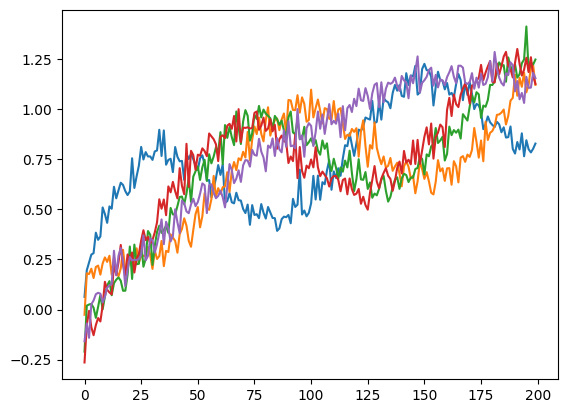

In [10]:
plt.plot(Y_train_ts.squeeze(-2)[50:55].mT)

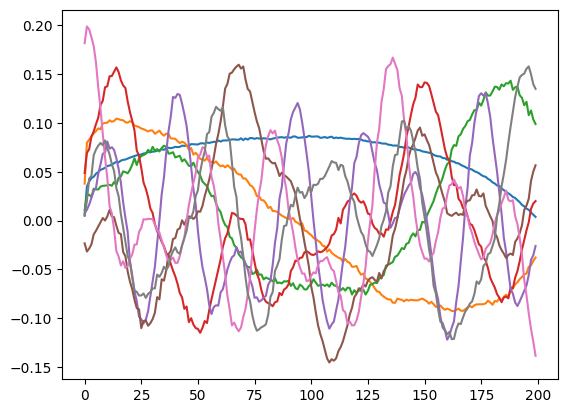

In [11]:
Y_train_ts_pca.shape
Y_pca._pca.components_
plt.plot(Y_pca._pca.components_.mT)

## Visualize test data

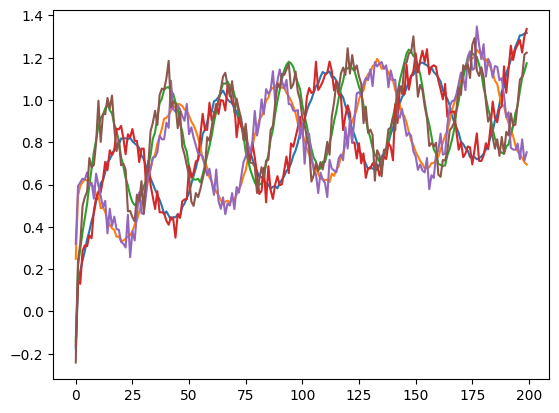

In [12]:
testidx = [in_sample[0], in_hull[0], out_hull[0]]

Y_test_decoded = Y_pca.decode(Y_test_ts_pca)
plt.plot(Y_test_decoded[testidx].squeeze(-2).mT)
plt.plot(Y_test_ts[testidx].squeeze(-2).mT)

In [13]:
# Variance explained in test data
1.0 - (Y_test_ts - Y_test_decoded).var() / Y_test_ts.var()

tensor(0.9694)

## Build and train unimodal model

In [14]:
#adam = pyro.optim.Adam({"lr": 0.001})
adam_seq = [pyro.optim.Adam({"lr": x}) for x in [0.001]]
elbo = pyro.infer.Trace_ELBO(num_particles = 1)

In [15]:
model = RegBNN.from_data(X_train, Y_train_ts_pca, hidden_widths = hidden_widths)
guide = RegBNNGuide(model)

#svi = pyro.infer.SVI(model, guide, adam, elbo)
hmc = pyro.infer.NUTS(model.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 49603.1 +/- 29433.3 (slope = -50501.300 +/- 429.261 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 18011.1 +/- 10064.1 (slope = -17258.518 +/- 151.155 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 7039.2 +/- 3641.5 (slope = -6245.547 +/- 54.289 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 3006.2 +/- 1375.5 (slope = -2350.582 +/- 24.119 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 1471.6 +/- 535.6 (slope = -899.788 +/- 14.168 loss/k-iter, p-value = 0.000) + 
Step 6000, Elbo loss: 861.4 +/- 245.5 (slope = -379.384 +/- 12.116 loss/k-iter, p-value = 0.000) + 
Step 7000, Elbo loss: 598.9 +/- 139.8 (slope = -168.650 +/- 10.991 loss/k-iter, p-value = 0.000) + 
Step 8000, Elbo loss: 463.0 +/- 101.4 (slope = -87.014 +/- 9.654 loss/k-iter, p-value = 0.000) + 
Step 9000, Elbo loss: 394.8 +/- 90.5 (slope = -56.131 +/- 9.256 loss/k-iter, p-value = 0.000) + 
Step 10000, Elbo loss: 350.9 +/- 80.3 (slope = -32.772 +/- 8.557 loss/k-iter, p-valu

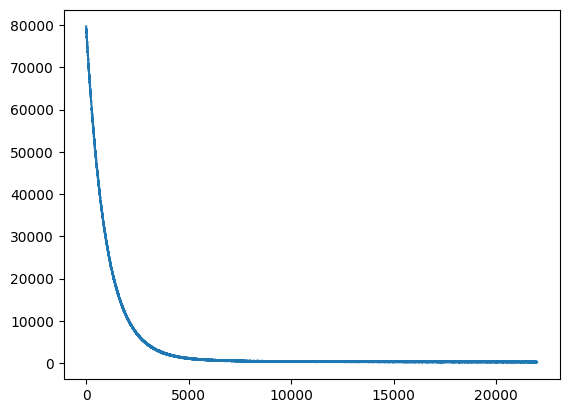

In [16]:
if method == "mcmc":
    mcmc = pyro.infer.MCMC(hmc, num_samples = 100, warmup_steps = 100)
    mcmc.run(X_pred = X_test)
    pred = Predictive(model, mcmc.get_samples())
    Y_pred_pca = pred.get_samples(X_pred = X_test)['mu_pred']
elif method == "svi":
    params = None
    losses = []
    for adam in adam_seq:
        svi = pyro.infer.SVI(model, guide, adam, elbo)
        params, new_losses = do_svi(svi, params = params)
        losses += new_losses
    plt.plot(losses)
    guide.eval()
    with param_store.scope(params):
        pred = Predictive(model, guide = guide, num_samples = 100)
        Y_pred_pca = pred.get_samples(X_pred = X_test)['mu_pred']
Y_pred = Y_pca.decode(Y_pred_pca)

In [17]:
def plot_predictions_ts(Y_test, Y_pred, series_idx):
    Y_true = Y_test[series_idx].squeeze()
    Y_pred = Y_pred[:,series_idx].squeeze(-2).mT
    # Set up figure/axes
    fig, ax = plt.subplots(figsize=(10, 5))
    ylims = [1.5*Y_pred.min().detach() - 0.5*Y_pred.max().detach(), 1.5*Y_pred.max().detach() - 0.5*Y_pred.min().detach()]
    plt.ylim(ylims)
    # Plot true function
    ax.plot(Y_true, 'k-', linewidth=3, label="true function", zorder = 20)
    # Plot data points
    ax.plot(Y_pred, 'b-', linewidth=1, alpha=0.5, label="estimates", zorder = 15)

def plot_predictions_pairs(Y_test, Y_pred, idx):
    Y_true = Y_test[idx]
    Y_pred = Y_pred[:,idx]
    colnames = [f"Y_{n}" for n in range(Y_pred.shape[-1])]
    data = pd.DataFrame(Y_pred, columns=colnames)
    data["Type"] = "Pred"
    data_true = pd.DataFrame(Y_true.unsqueeze(0), columns=colnames)
    data_true["Type"] = "True"
    g = sns.pairplot(pd.concat([data, data_true]), hue="Type", height = 1.5, diag_kind="hist")

In [18]:
random.shuffle(in_sample)
random.shuffle(in_hull)
random.shuffle(out_hull)

idx = 0

### In-sample

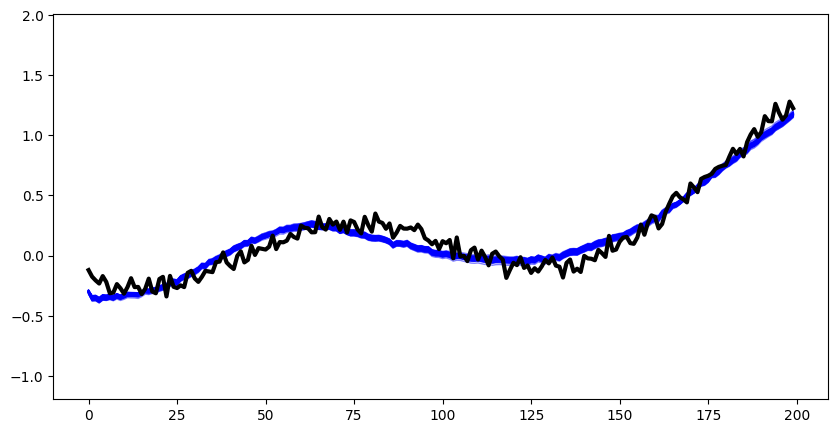

In [19]:
plot_predictions_ts(Y_test_ts, Y_pred, in_sample[idx])

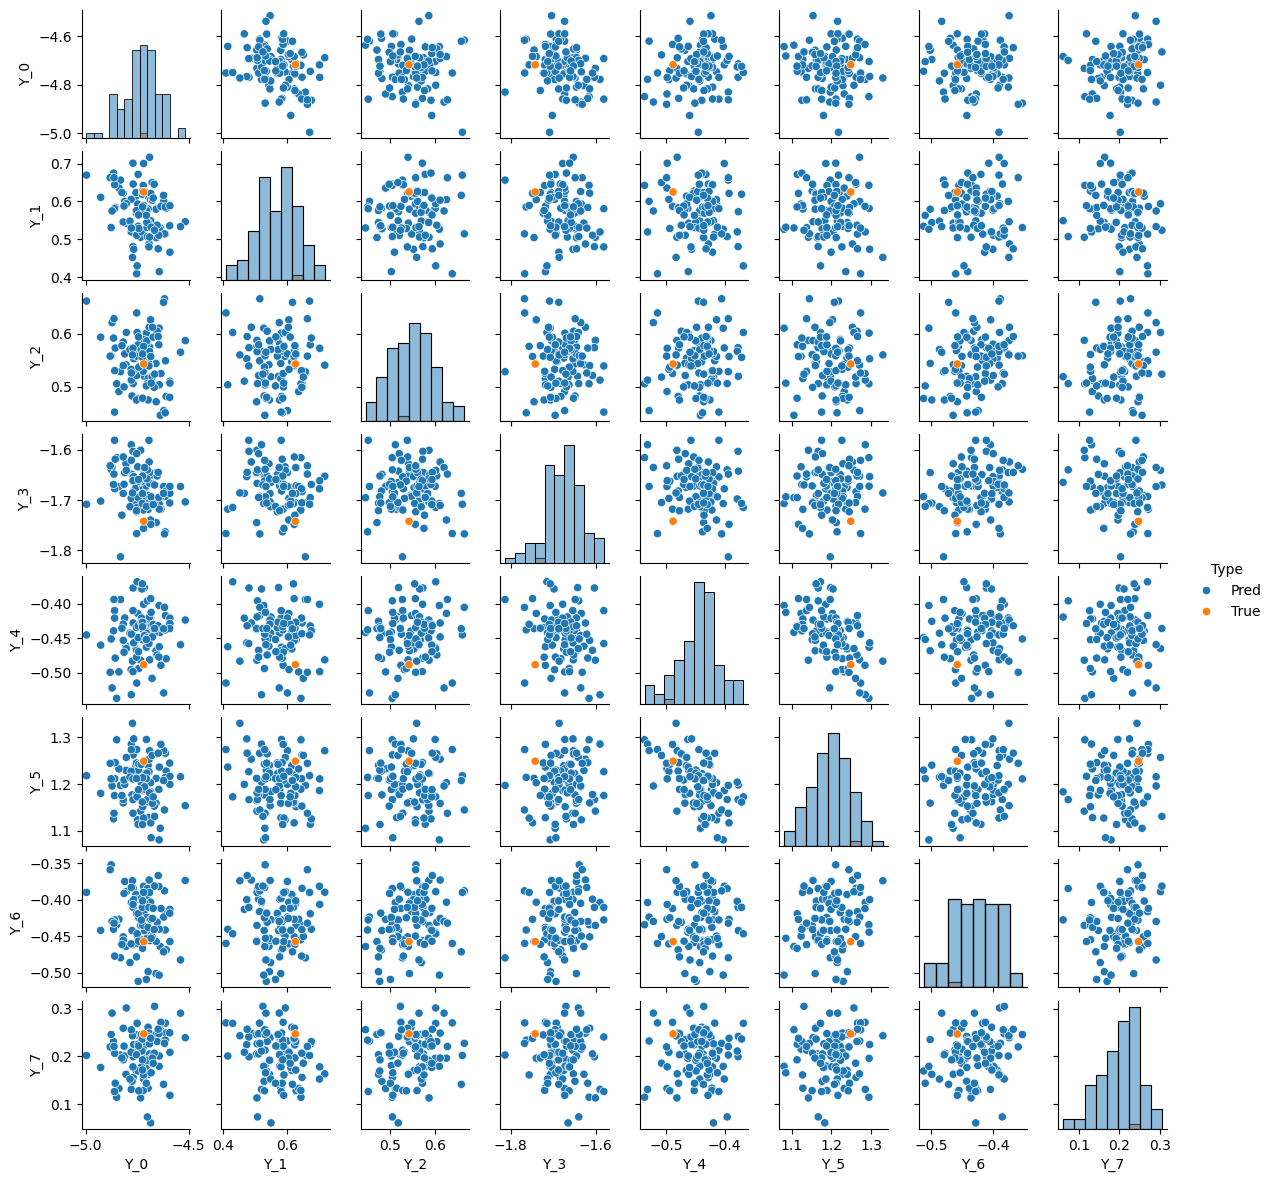

In [20]:
plot_predictions_pairs(Y_test_ts_pca, Y_pred_pca, in_sample[idx])

### Out of sample but within the convex hull

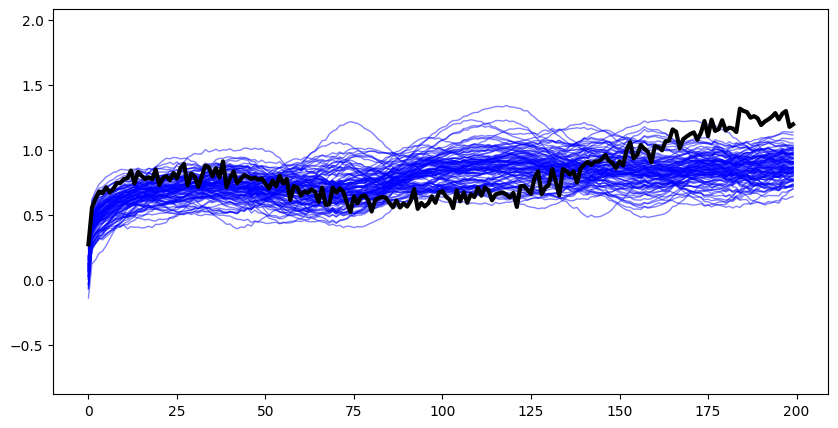

In [21]:
plot_predictions_ts(Y_test_ts, Y_pred, in_hull[idx])

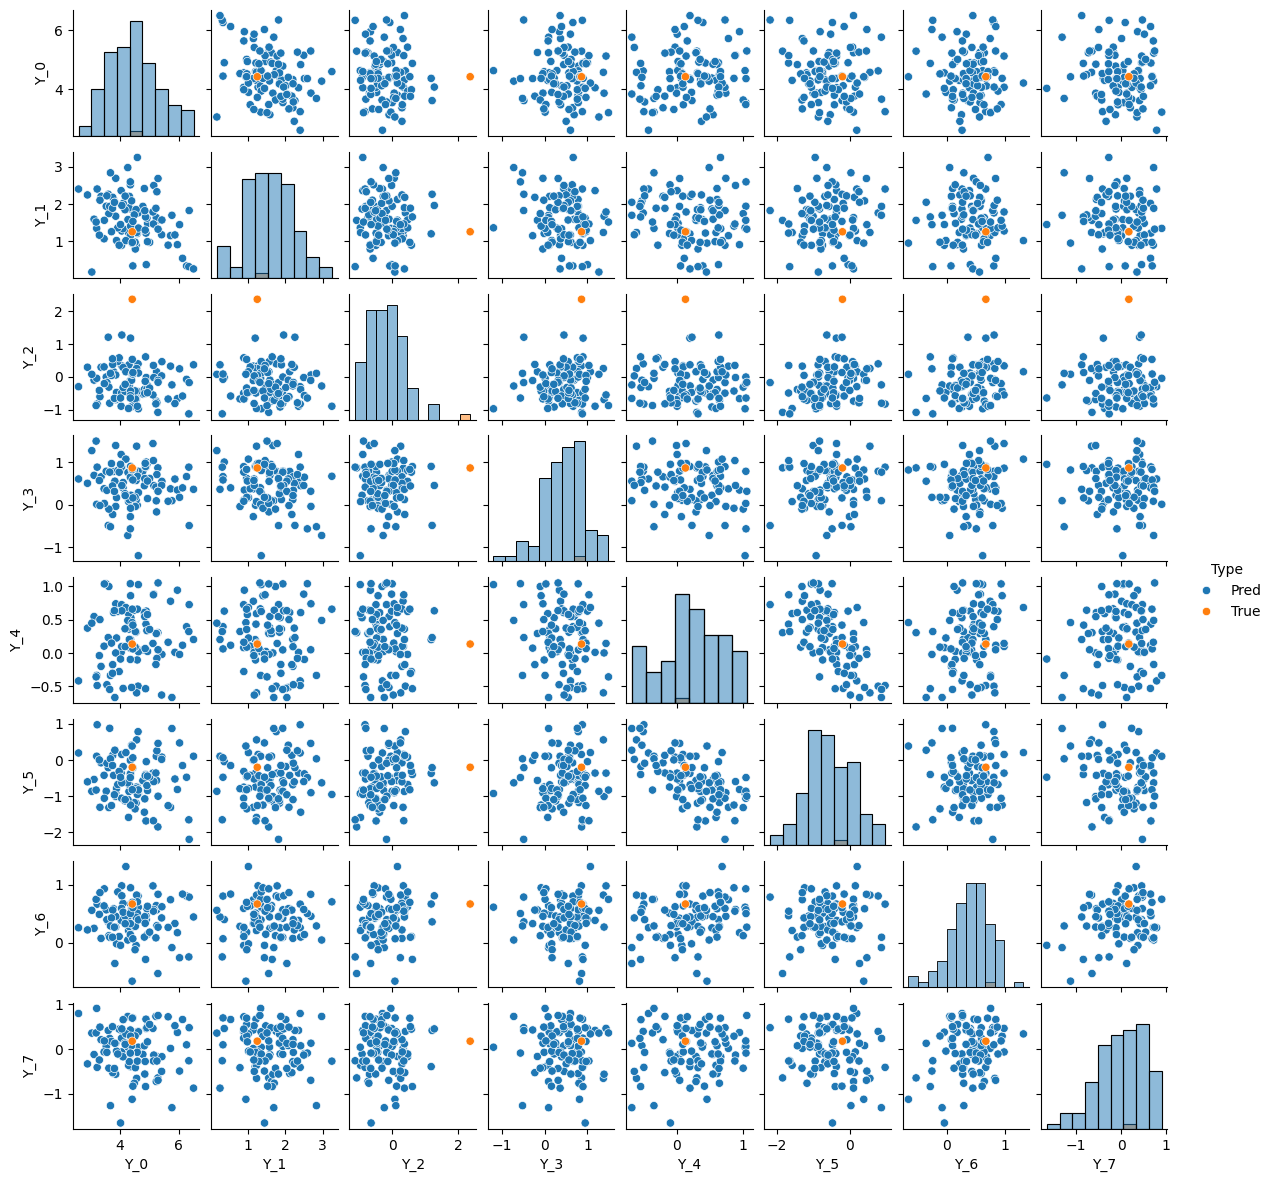

In [22]:
plot_predictions_pairs(Y_test_ts_pca, Y_pred_pca, in_hull[idx])

### Out of the convex hull

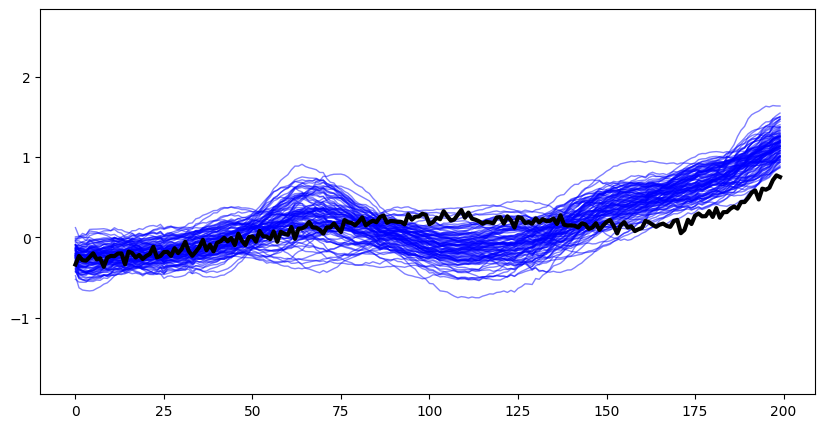

In [23]:
plot_predictions_ts(Y_test_ts, Y_pred, out_hull[idx])

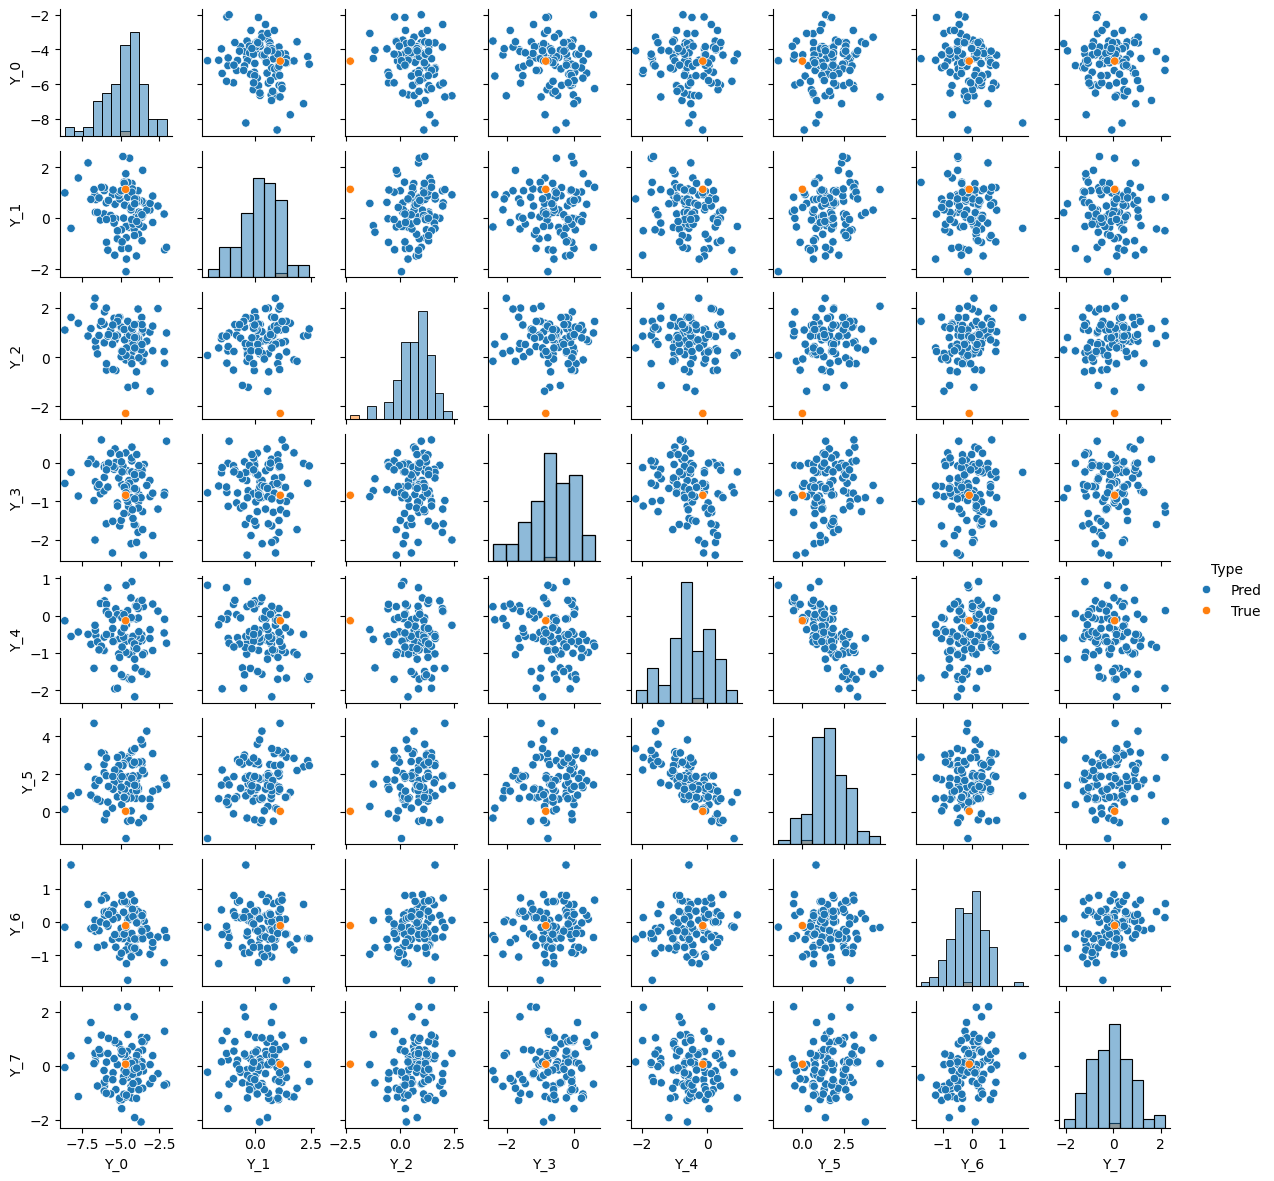

In [24]:
plot_predictions_pairs(Y_test_ts_pca, Y_pred_pca, out_hull[idx])

## Build and train a multimodal model

Set up multimodal training data:
* With the original X_train
* With an expanded X_train that significantly grows the convex hull of 

In [25]:
model_mm = LayeredRegBNN.from_data(X_train, Y_train_ts_pca, [X_train_full], [Y_train_full_sc], hidden_widths = hidden_widths)
guide_mm = LayeredRegBNNGuide(model_mm)

#svi_mm = pyro.infer.SVI(model_mm, guide_mm, adam, elbo)
hmc_mm = pyro.infer.NUTS(model_mm.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 52444.0 +/- 28320.3 (slope = -48606.783 +/- 405.805 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 21316.3 +/- 10328.3 (slope = -17725.904 +/- 148.397 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 9766.5 +/- 4013.0 (slope = -6884.720 +/- 58.850 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 5131.7 +/- 1692.5 (slope = -2882.539 +/- 33.241 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 3137.5 +/- 799.8 (slope = -1323.269 +/- 25.799 loss/k-iter, p-value = 0.000) + 
Step 6000, Elbo loss: 2188.8 +/- 436.7 (slope = -657.046 +/- 23.677 loss/k-iter, p-value = 0.000) + 
Step 7000, Elbo loss: 1680.9 +/- 296.2 (slope = -370.951 +/- 22.413 loss/k-iter, p-value = 0.000) + 
Step 8000, Elbo loss: 1382.3 +/- 248.0 (slope = -257.446 +/- 21.754 loss/k-iter, p-value = 0.000) + 
Step 9000, Elbo loss: 1175.1 +/- 228.4 (slope = -183.556 +/- 22.170 loss/k-iter, p-value = 0.000) + 
Step 10000, Elbo loss: 1034.1 +/- 209.8 (slope = -103.487 +/- 22.041 loss/

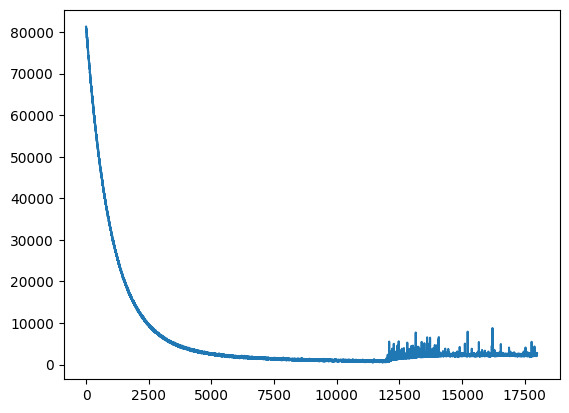

In [26]:
if method == "mcmc":
    mcmc_mm = pyro.infer.MCMC(hmc_mm, num_samples = 100, warmup_steps = 100)
    mcmc_mm.run(X_pred = X_test)
    pred_mm = Predictive(model_mm, mcmc_mm.get_samples())
    Y_pred_mm_pca = pred_mm.get_samples(X_pred = X_test)['mu_pred']
elif method == "svi":
    params_mm = None
    losses_mm = []
    for adam in adam_seq:
        #svi_mm_aux = pyro.infer.SVI(model_mm.expose_aux(), guide_mm.expose_aux(), adam, elbo)
        #params_mm, new_losses = do_svi(svi_mm_aux, check_interval = 1000, params = params_mm)
        #losses_mm += new_losses
        #svi_mm_main = pyro.infer.SVI(model_mm.expose_main(), guide_mm.expose_main(), adam, elbo)
        #params_mm, new_losses = do_svi(svi_mm_main, check_interval = 1000, params = params_mm)
        #losses_mm += new_losses
        svi_mm = pyro.infer.SVI(model_mm, guide_mm, adam, elbo)
        params_mm, new_losses = do_svi(svi_mm, check_interval = 1000, params = params_mm)
        losses_mm += new_losses
    plt.plot(losses_mm)
    guide_mm.eval()
    with param_store.scope(params_mm):
        pred_mm = Predictive(model_mm, guide = guide_mm, num_samples = 100)
        Y_pred_mm_pca = pred_mm.get_samples(X_pred = X_test)['mu_pred']
Y_pred_mm = Y_pca.decode(Y_pred_mm_pca)

### In-sample

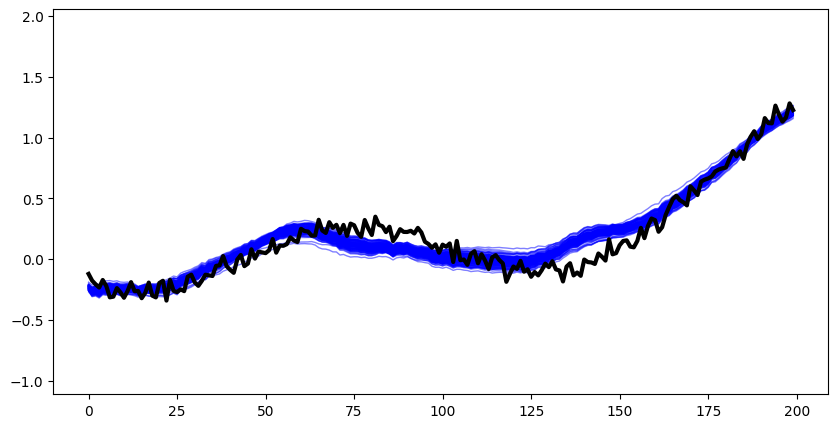

In [27]:
plot_predictions_ts(Y_test_ts, Y_pred_mm, in_sample[idx])

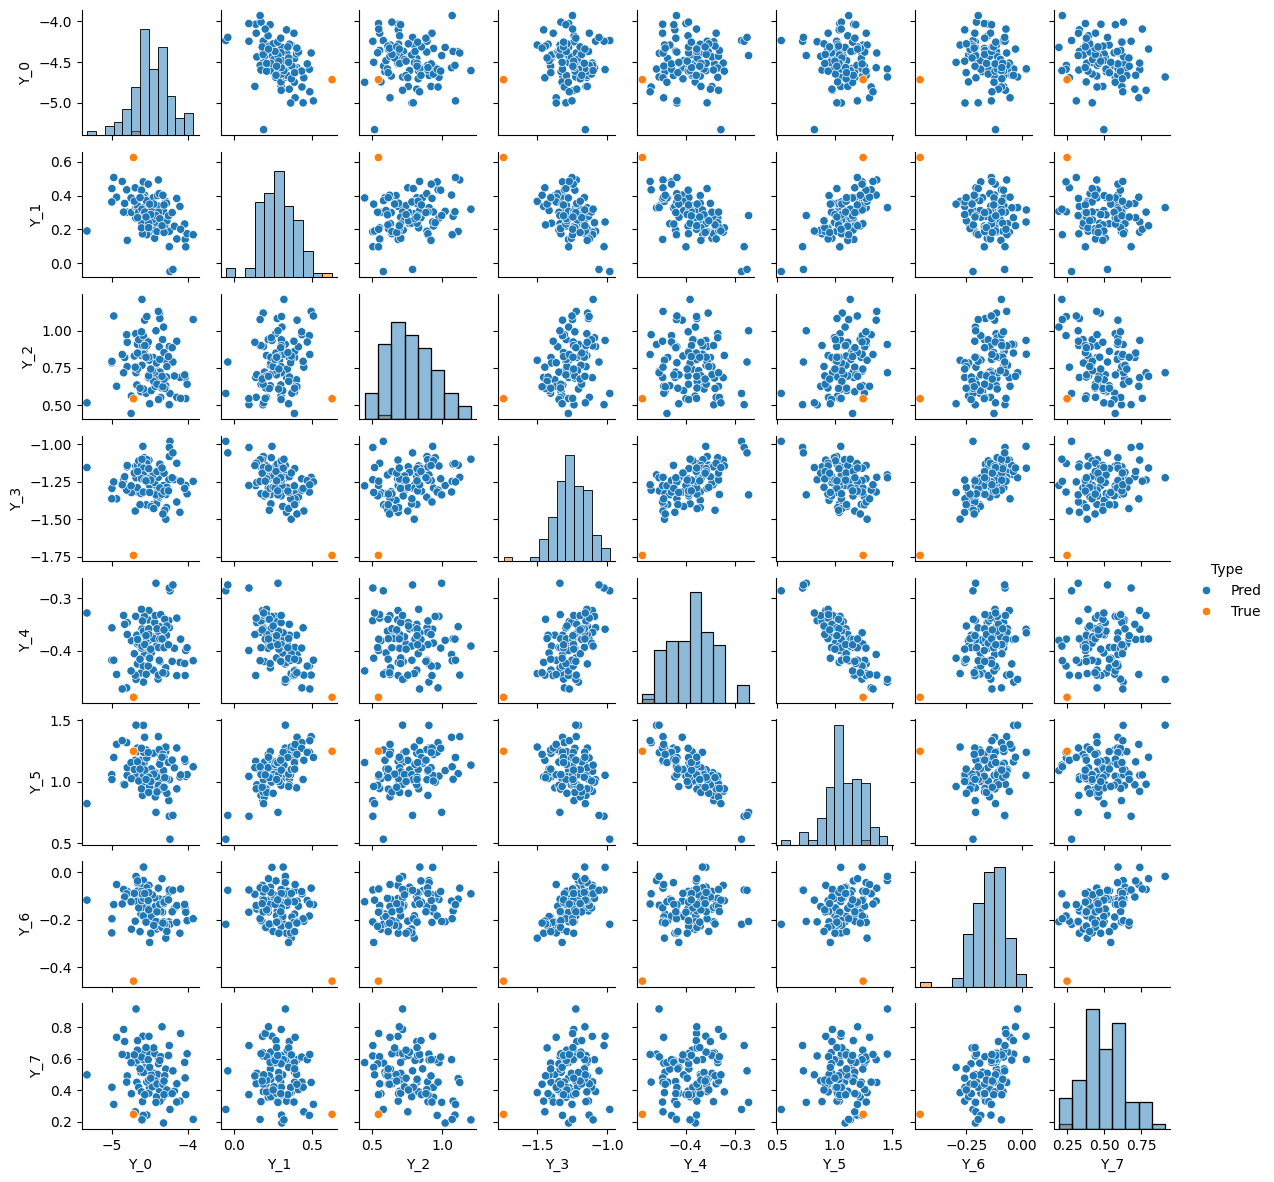

In [28]:
plot_predictions_pairs(Y_test_ts_pca, Y_pred_mm_pca, in_sample[idx])

### Out of sample but within the convex hull

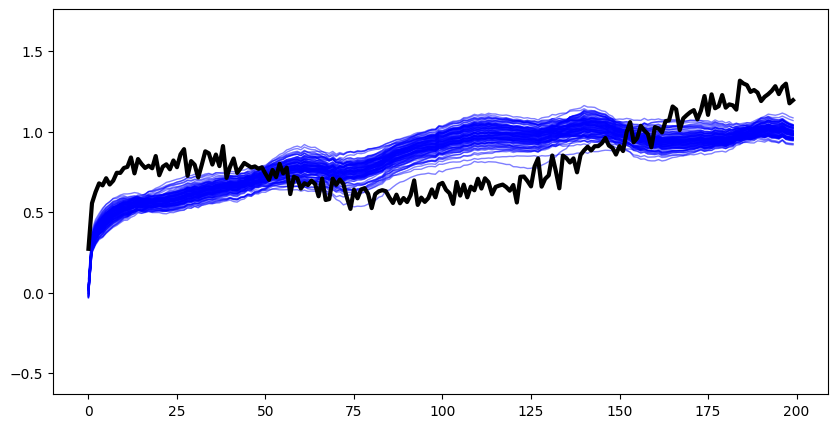

In [29]:
plot_predictions_ts(Y_test_ts, Y_pred_mm, in_hull[idx])

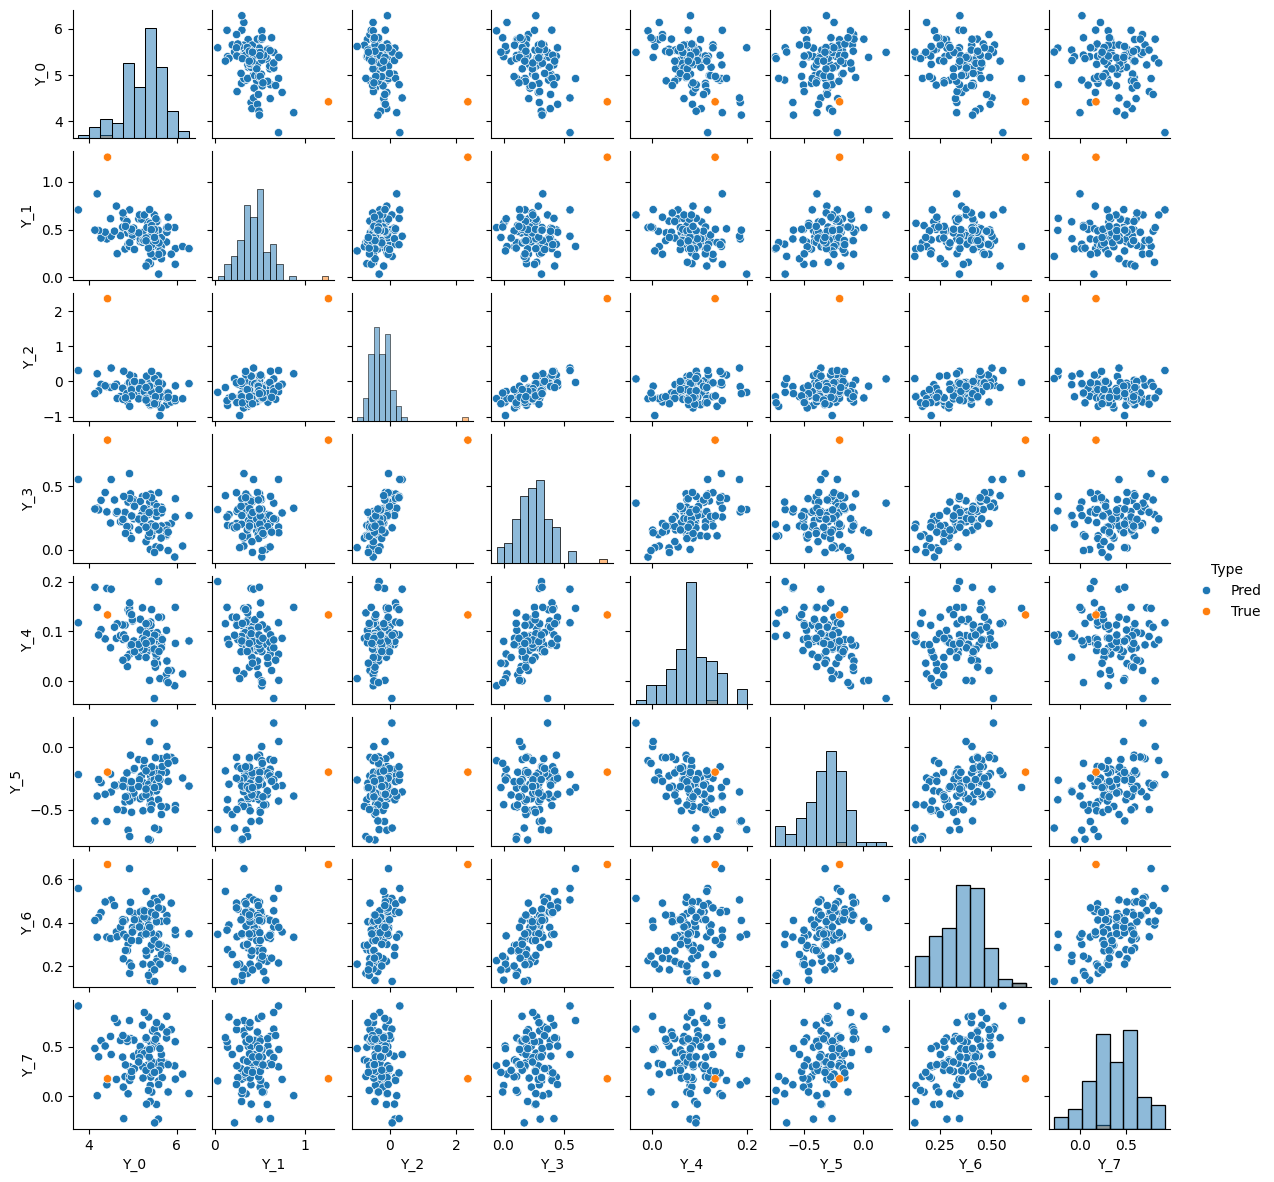

In [30]:
plot_predictions_pairs(Y_test_ts_pca, Y_pred_mm_pca, in_hull[idx])

### Out of the convex hull

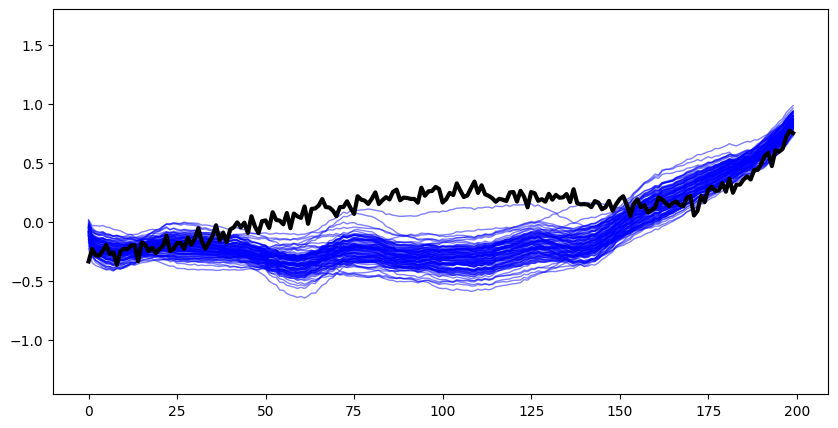

In [31]:
plot_predictions_ts(Y_test_ts, Y_pred_mm, out_hull[idx])

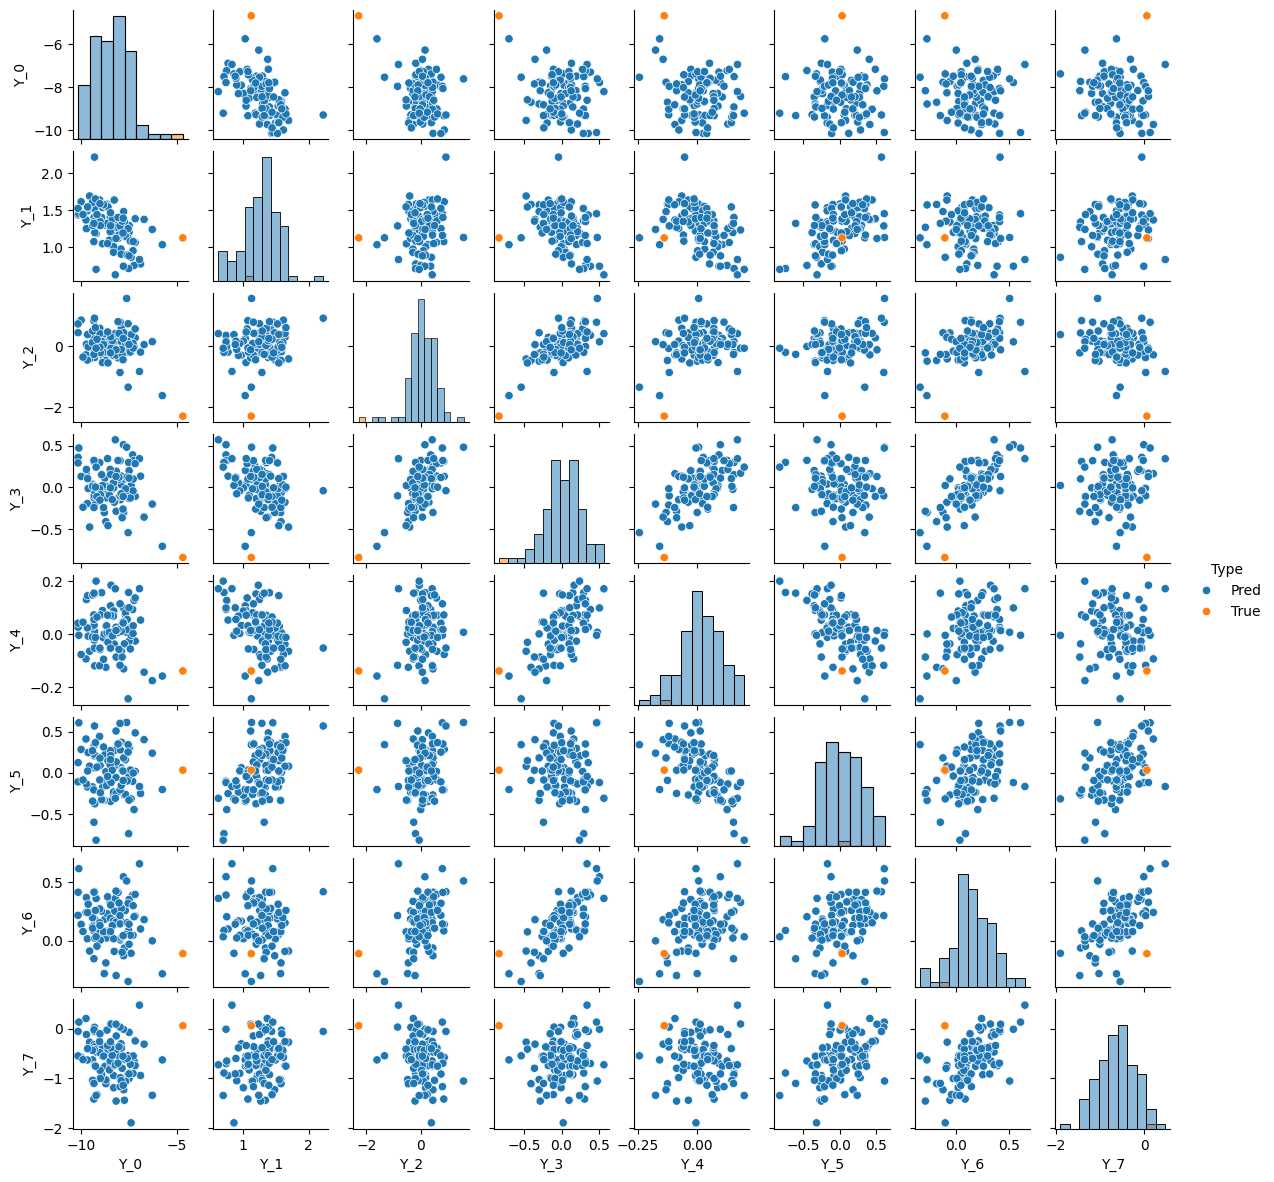

In [32]:
plot_predictions_pairs(Y_test_ts_pca, Y_pred_mm_pca, out_hull[idx])

## Compare unimodal and multimodal models on the whole

Compare bias and uncertainty for in-sample, in-hull and out of hull test points

### Bias

Difference between true point and mean of posterior predictions

Text(0, 0.5, 'Multimodal')

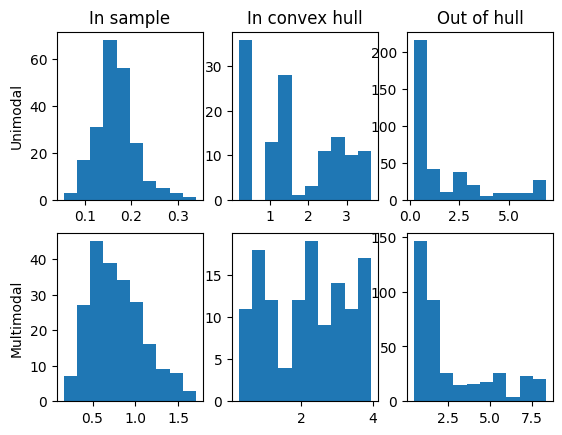

In [33]:
Y_bias_pca = (Y_pred_pca.mean(dim=0) - Y_test_ts_pca).pow(2).sum(dim=-1).sqrt() # Combine bias in Euclidian distance fashion
Y_bias_mm_pca = (Y_pred_mm_pca.mean(dim=0) - Y_test_ts_pca).pow(2).sum(dim=-1).sqrt()

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_bias_pca[in_sample])
# Unimodal, in hull
axs[0,1].hist(Y_bias_pca[in_hull])
# Unimodal, out hull
axs[0,2].hist(Y_bias_pca[out_hull])
# Multimodal, in sample
axs[1,0].hist(Y_bias_mm_pca[in_sample])
# Multimodal, in hull
axs[1,1].hist(Y_bias_mm_pca[in_hull])
# Multimodal, out hull
axs[1,2].hist(Y_bias_mm_pca[out_hull])

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("Multimodal")

Text(0, 0.5, 'Multimodal')

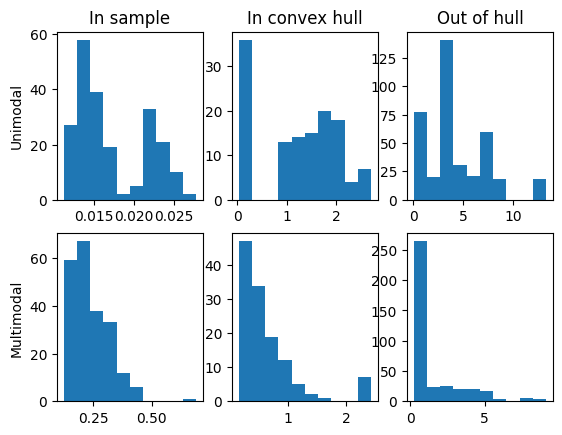

In [34]:
Y_var_pca = Y_pred_pca.var(dim=0).sum(dim=-1) # Add marginal variances
Y_var_mm_pca = Y_pred_mm_pca.var(dim=0).sum(dim=-1)

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_var_pca[in_sample])
# Unimodal, in hull
axs[0,1].hist(Y_var_pca[in_hull])
# Unimodal, out hull
axs[0,2].hist(Y_var_pca[out_hull])
# Multimodal, in sample
axs[1,0].hist(Y_var_mm_pca[in_sample])
# Multimodal, in hull
axs[1,1].hist(Y_var_mm_pca[in_hull])
# Multimodal, out hull
axs[1,2].hist(Y_var_mm_pca[out_hull])

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("Multimodal")

## "Fake" multimodal model

Skip the auxiliary surrogate model and just pass the true aux variables in as training features.

In [35]:
X_train_fakemm = torch.cat([X_train, Y_train_sc], dim=-1)
X_test_fakemm = torch.cat([X_test, Y_test_sc], dim=-1)

In [36]:
model_fakemm = RegBNN.from_data(X_train_fakemm, Y_train_ts_pca, hidden_widths = hidden_widths)
guide_fakemm = RegBNNGuide(model_fakemm)

#svi_fakemm = pyro.infer.SVI(model_fakemm, guide_fakemm, adam, elbo)
hmc_fakemm = pyro.infer.NUTS(model_fakemm.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 50004.7 +/- 29783.1 (slope = -51106.190 +/- 432.202 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 17854.2 +/- 10334.1 (slope = -17720.495 +/- 155.614 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 6684.2 +/- 3634.7 (slope = -6230.896 +/- 55.540 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 2721.0 +/- 1302.5 (slope = -2225.378 +/- 23.003 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 1294.8 +/- 477.3 (slope = -804.405 +/- 11.952 loss/k-iter, p-value = 0.000) + 
Step 6000, Elbo loss: 773.3 +/- 201.6 (slope = -315.225 +/- 9.485 loss/k-iter, p-value = 0.000) + 
Step 7000, Elbo loss: 567.2 +/- 107.3 (slope = -126.647 +/- 8.605 loss/k-iter, p-value = 0.000) + 
Step 8000, Elbo loss: 471.7 +/- 83.4 (slope = -64.353 +/- 8.179 loss/k-iter, p-value = 0.000) + 
Step 9000, Elbo loss: 425.8 +/- 76.8 (slope = -35.913 +/- 8.107 loss/k-iter, p-value = 0.000) + 
Step 10000, Elbo loss: 399.7 +/- 76.1 (slope = -23.531 +/- 8.211 loss/k-iter, p-value =

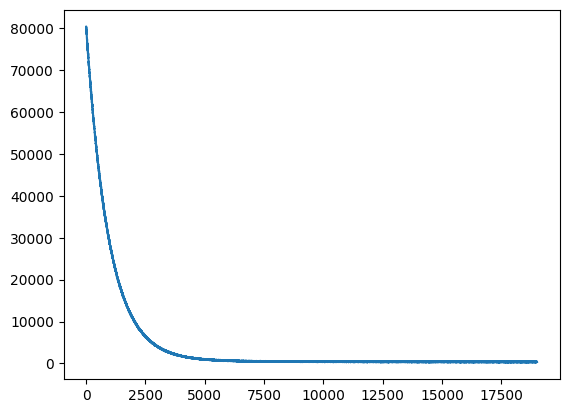

In [37]:
if method == "mcmc":
    mcmc_fakemm = pyro.infer.MCMC(hmc_fakemm, num_samples = 100, warmup_steps = 100)
    mcmc_fakemm.run(X_pred = X_test_fakemm)
    pred_fakemm = Predictive(model_fakemm, mcmc_fakemm.get_samples())
    Y_pred_fakemm_pca = pred.get_samples(X_pred = X_test_fakemm)['mu_pred']
elif method == "svi":
    params_fakemm = None
    losses_fakemm = []
    for adam in adam_seq:
        svi_fakemm = pyro.infer.SVI(model_fakemm, guide_fakemm, adam, elbo)
        params_fakemm, new_losses = do_svi(svi_fakemm, params = params_fakemm)
        losses_fakemm += new_losses
    plt.plot(losses_fakemm)
    guide_fakemm.eval()
    with param_store.scope(params_fakemm):
        pred_fakemm = Predictive(model_fakemm, guide = guide_fakemm, num_samples = 100)
        Y_pred_fakemm_pca = pred_fakemm.get_samples(X_pred = X_test_fakemm)['mu_pred']
Y_pred_fakemm = Y_pca.decode(Y_pred_fakemm_pca)

### In sample

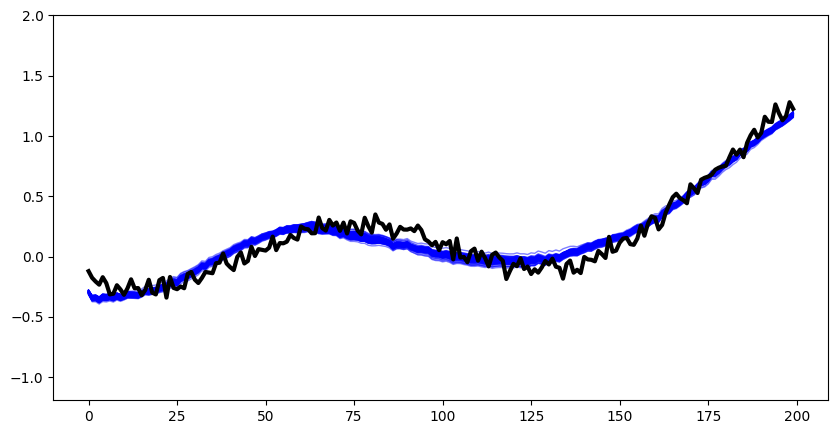

In [38]:
plot_predictions_ts(Y_test_ts, Y_pred_fakemm, in_sample[idx])

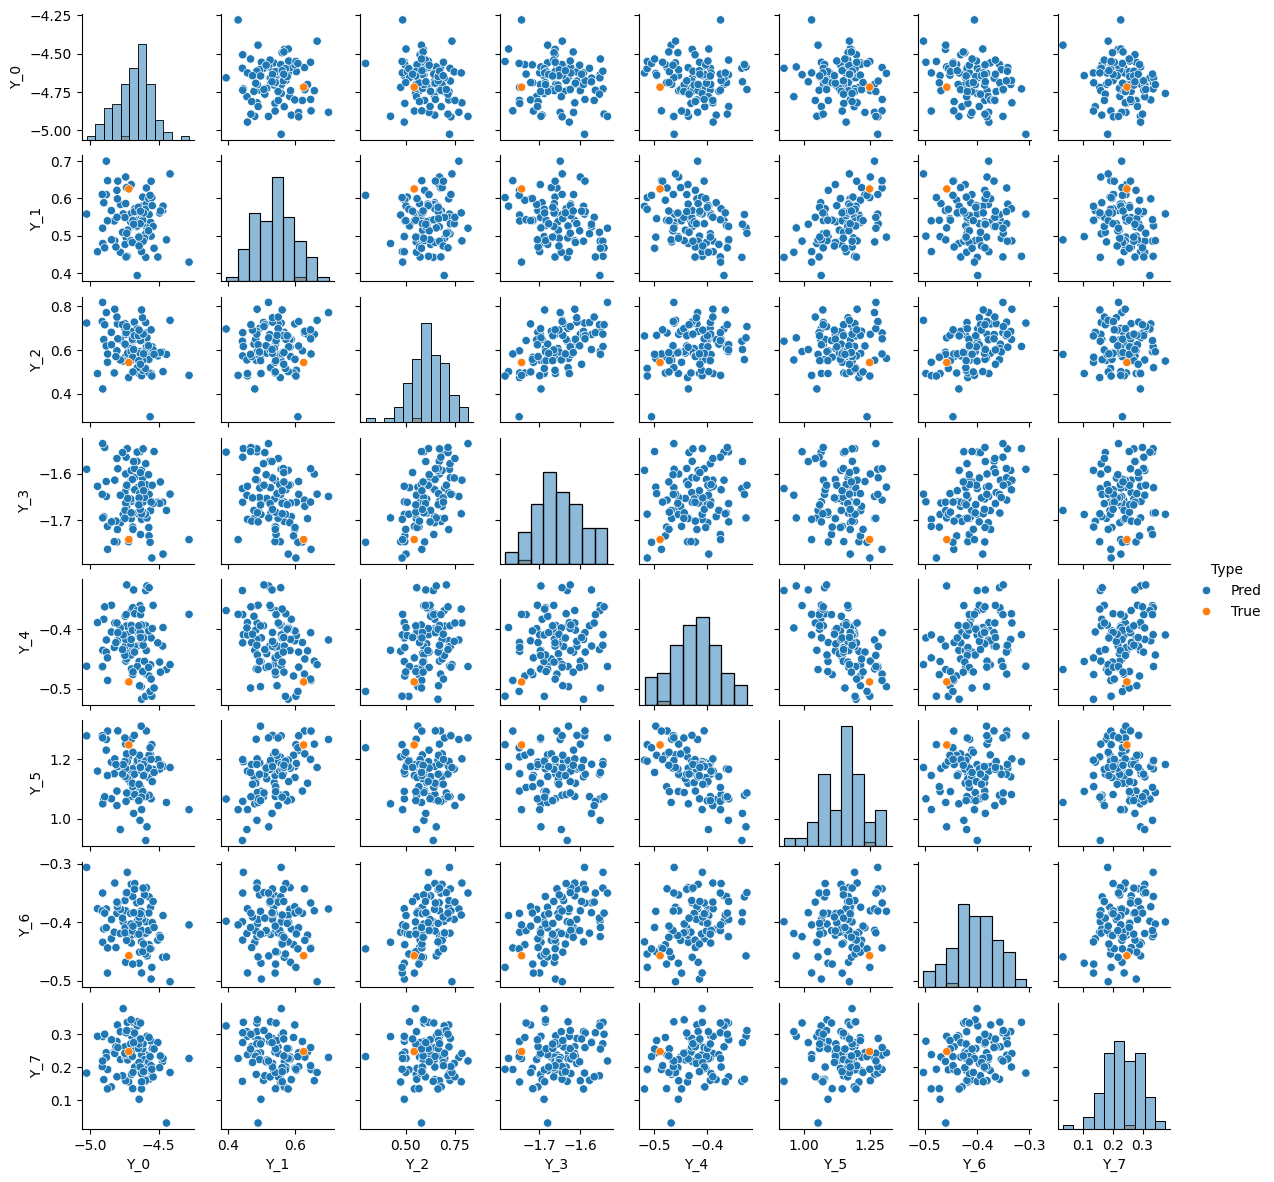

In [39]:
plot_predictions_pairs(Y_test_ts_pca, Y_pred_fakemm_pca, in_sample[idx])

### Out of sample but in convex hull

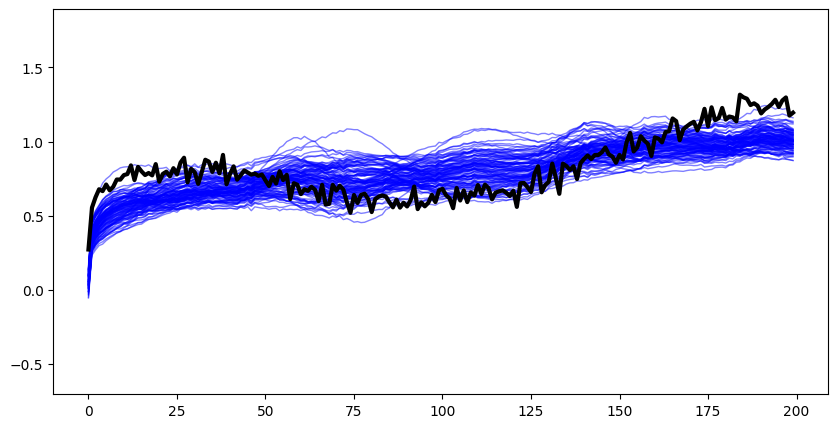

In [40]:
plot_predictions_ts(Y_test_ts, Y_pred_fakemm, in_hull[idx])

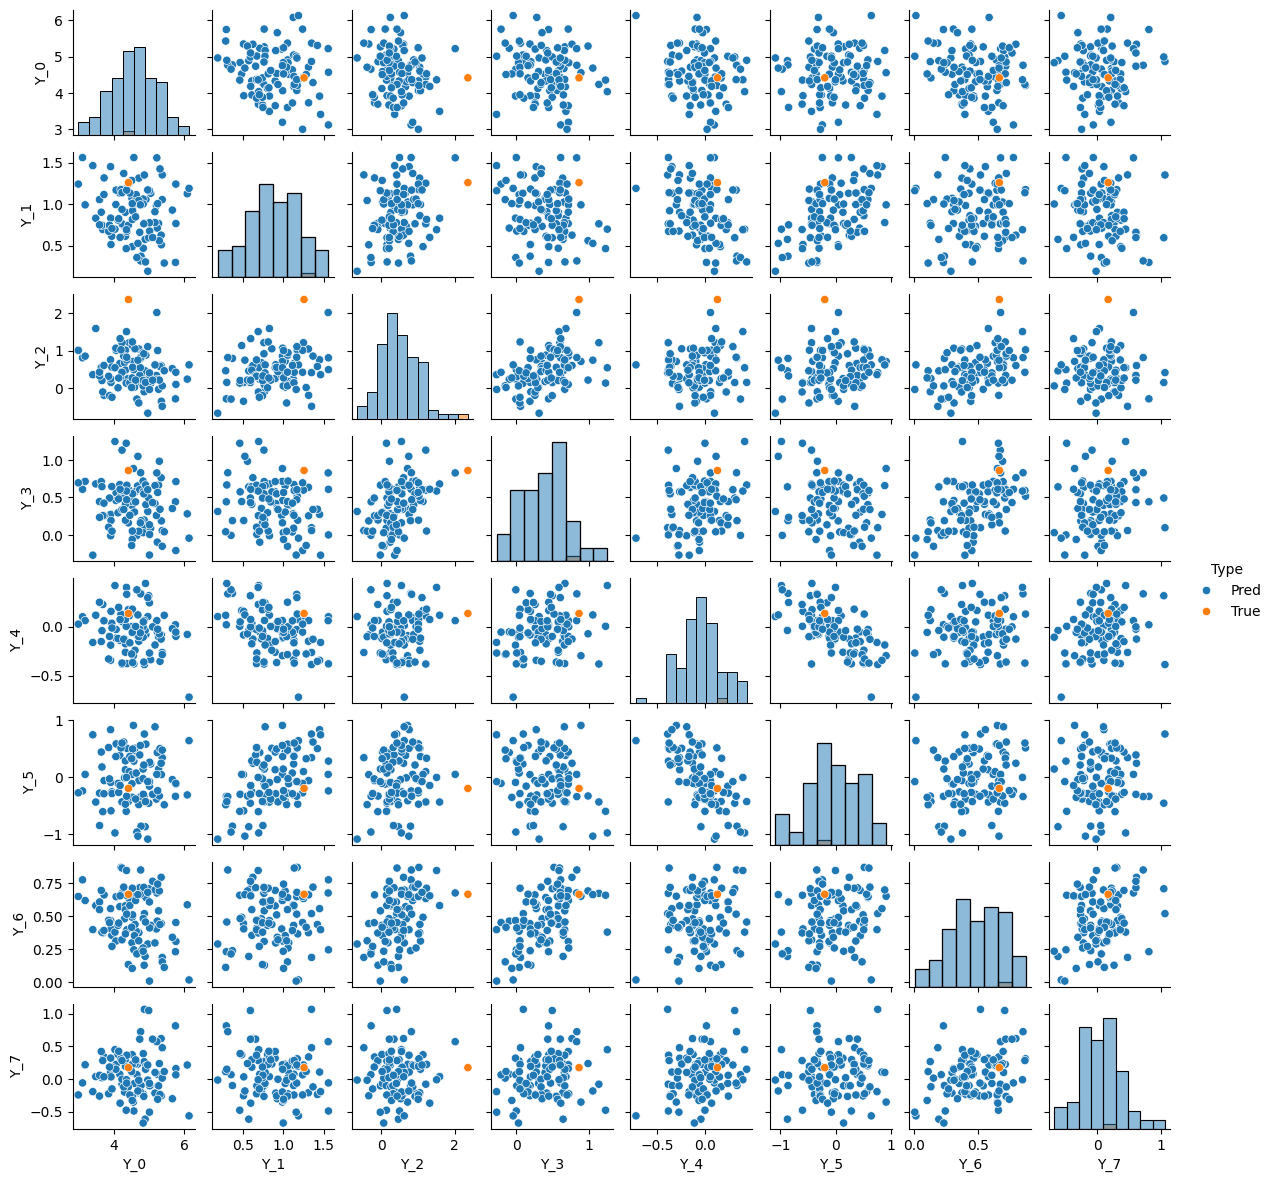

In [41]:
plot_predictions_pairs(Y_test_ts_pca, Y_pred_fakemm_pca, in_hull[idx])

### Out of convex hull

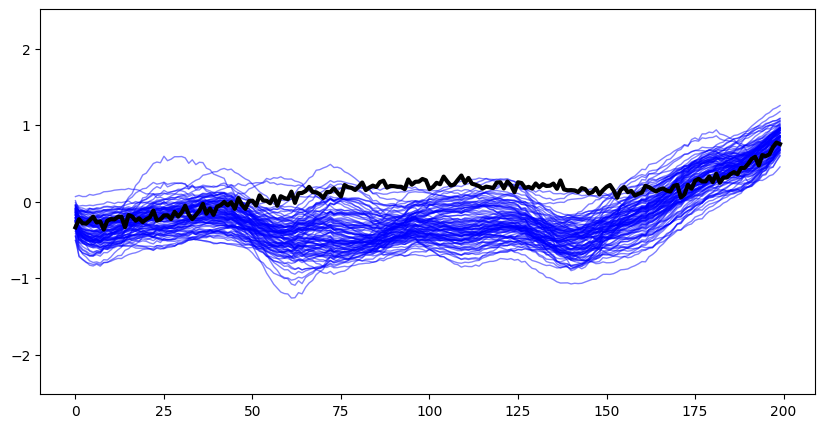

In [42]:
plot_predictions_ts(Y_test_ts, Y_pred_fakemm, out_hull[idx])

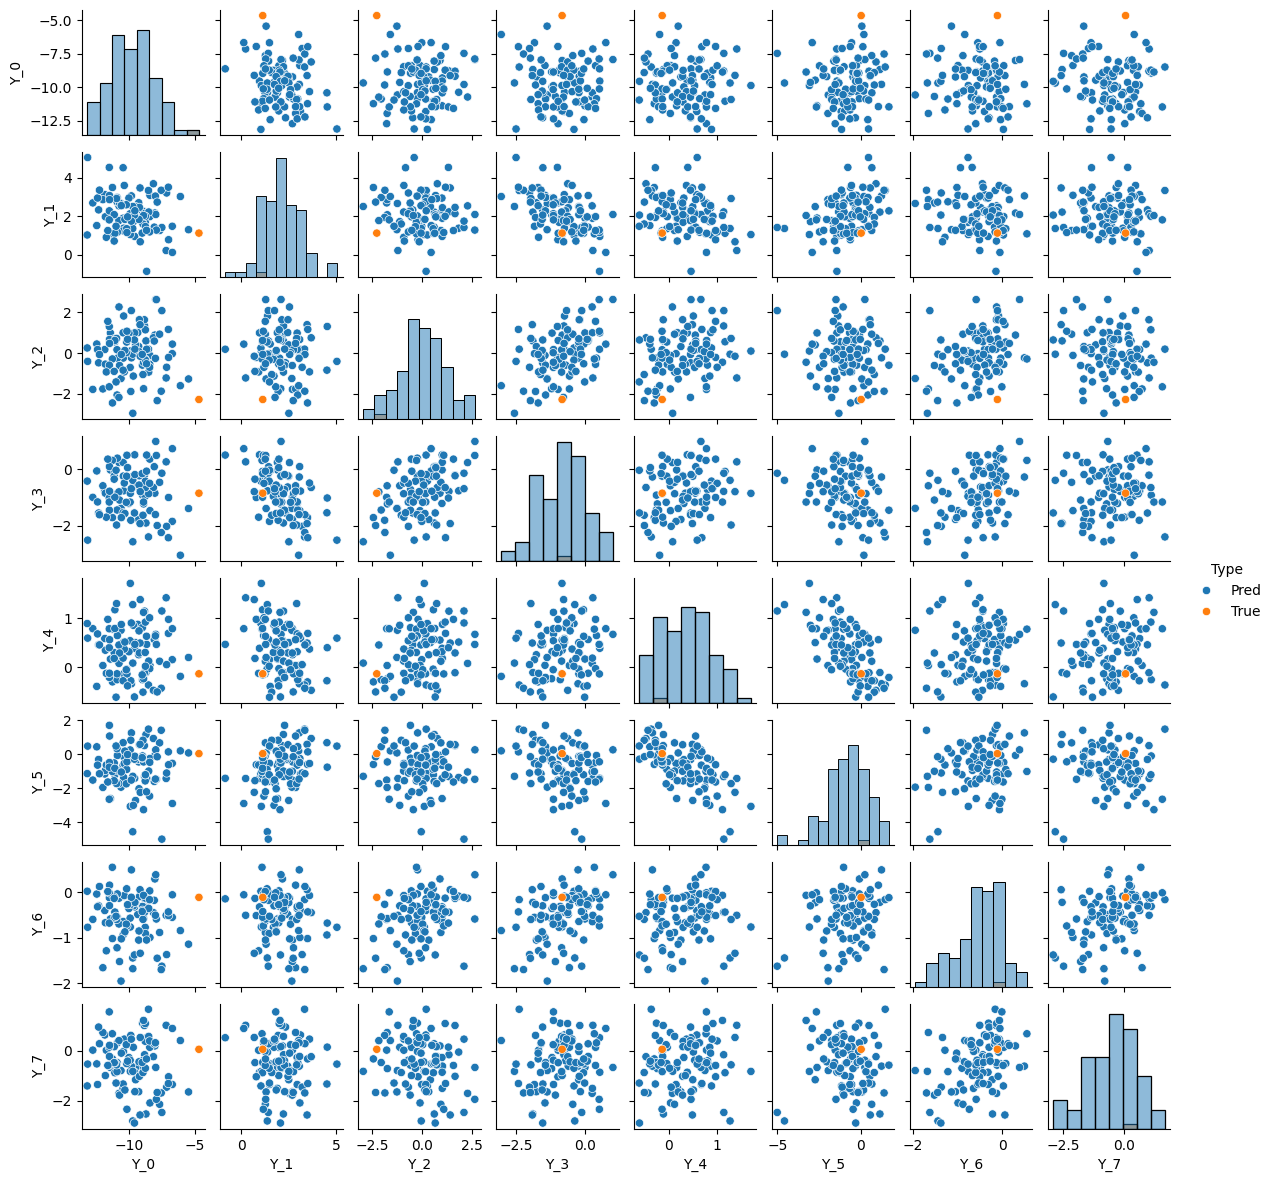

In [43]:
plot_predictions_pairs(Y_test_ts_pca, Y_pred_fakemm_pca, out_hull[idx])

### Evaluate Fake multimodal model vs unimodal model overall

#### Bias

Text(0, 0.5, "'Fake' Multimodal")

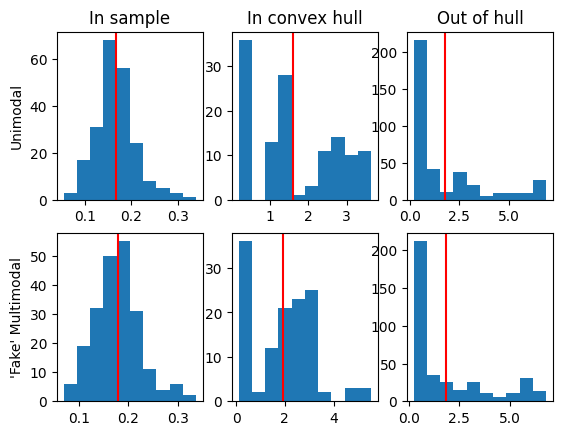

In [44]:
Y_bias_fakemm_pca = (Y_pred_fakemm_pca.mean(dim=0) - Y_test_ts_pca).pow(2).sum(dim = -1).sqrt()

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_bias_pca[in_sample])
axs[0,0].axvline(Y_bias_pca[in_sample].mean(), color="red")
# Unimodal, in hull
axs[0,1].hist(Y_bias_pca[in_hull])
axs[0,1].axvline(Y_bias_pca[in_hull].mean(), color="red")
# Unimodal, out hull
axs[0,2].hist(Y_bias_pca[out_hull])
axs[0,2].axvline(Y_bias_pca[out_hull].mean(), color="red")
# Multimodal, in sample
axs[1,0].hist(Y_bias_fakemm_pca[in_sample])
axs[1,0].axvline(Y_bias_fakemm_pca[in_sample].mean(), color="red")
# Multimodal, in hull
axs[1,1].hist(Y_bias_fakemm_pca[in_hull])
axs[1,1].axvline(Y_bias_fakemm_pca[in_hull].mean(), color="red")
# Multimodal, out hull
axs[1,2].hist(Y_bias_fakemm_pca[out_hull])
axs[1,2].axvline(Y_bias_fakemm_pca[out_hull].mean(), color="red")

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("'Fake' Multimodal")

#### Variance

Text(0, 0.5, "'Fake' Multimodal")

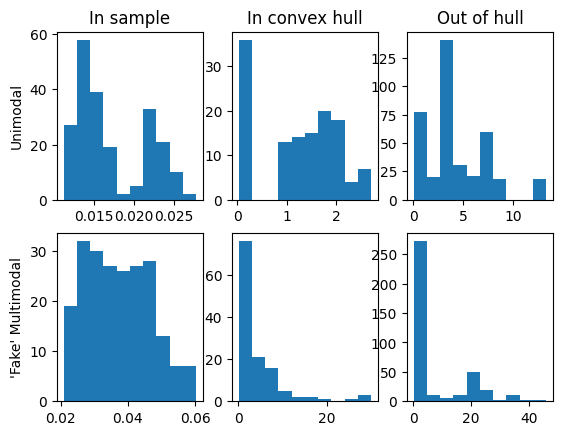

In [45]:

Y_var_fakemm_pca = Y_pred_fakemm_pca.var(dim=0).sum(dim=-1)

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_var_pca[in_sample])
# Unimodal, in hull
axs[0,1].hist(Y_var_pca[in_hull])
# Unimodal, out hull
axs[0,2].hist(Y_var_pca[out_hull])
# Multimodal, in sample
axs[1,0].hist(Y_var_fakemm_pca[in_sample])
# Multimodal, in hull
axs[1,1].hist(Y_var_fakemm_pca[in_hull])
# Multimodal, out hull
axs[1,2].hist(Y_var_fakemm_pca[out_hull])

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("'Fake' Multimodal")

#### Normalized Error

Text(0, 0.5, "'Fake' Multimodal")

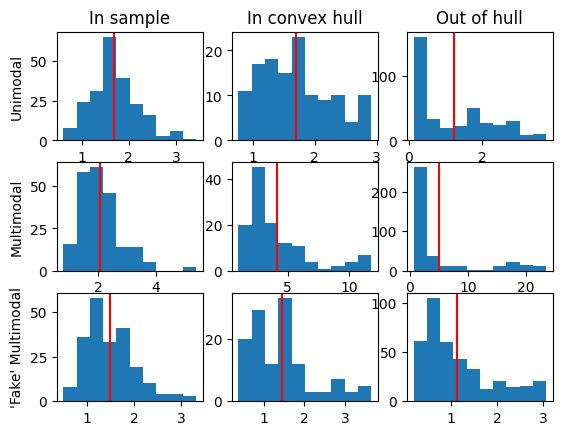

In [46]:
def mv_zscore(Y: torch.Tensor, mean: torch.Tensor, cov: torch.Tensor) -> torch.Tensor:
    """
    Y.shape == (*batch_dims, p)
    mean.shape == (*batch_dims, p)
    cov.shape == (*batch_dims, p, p)
    """
    p = Y.shape[-1]
    return (((Y - mean).unsqueeze(-2) @ cov.inverse() @ (Y - mean).unsqueeze(-1)).squeeze(-1).squeeze(-1) / p).sqrt()

#Y_zscore_pca = Y_bias_pca / Y_var_pca.sqrt()
#Y_zscore_fakemm_pca = Y_bias_fakemm_pca / Y_var_fakemm_pca.sqrt()
Y_mean_pca = Y_pred_pca.mean(dim=0)
Y_mean_mm_pca = Y_pred_mm_pca.mean(dim=0)
Y_mean_fakemm_pca = Y_pred_fakemm_pca.mean(dim=0)
Y_cov_pca = batch_cov(Y_pred_pca.permute(1,2,0))
Y_cov_mm_pca = batch_cov(Y_pred_mm_pca.permute(1,2,0))
Y_cov_fakemm_pca = batch_cov(Y_pred_fakemm_pca.permute(1,2,0))
Y_zscore_pca = mv_zscore(Y_test_ts_pca, Y_mean_pca, Y_cov_pca)
Y_zscore_mm_pca = mv_zscore(Y_test_ts_pca, Y_mean_mm_pca, Y_cov_mm_pca)
Y_zscore_fakemm_pca = mv_zscore(Y_test_ts_pca, Y_mean_fakemm_pca, Y_cov_fakemm_pca)


fig, axs = plt.subplots(3,3)
# Unimodal, in sample
axs[0,0].hist(Y_zscore_pca[in_sample])
axs[0,0].axvline(Y_zscore_pca[in_sample].mean(), color="red")
# Unimodal, in hull
axs[0,1].hist(Y_zscore_pca[in_hull])
axs[0,1].axvline(Y_zscore_pca[in_hull].mean(), color="red")
# Unimodal, out hull
axs[0,2].hist(Y_zscore_pca[out_hull])
axs[0,2].axvline(Y_zscore_pca[out_hull].mean(), color="red")
# Multimodal, in sample
axs[1,0].hist(Y_zscore_mm_pca[in_sample])
axs[1,0].axvline(Y_zscore_mm_pca[in_sample].mean(), color="red")
# Multimodal, in hull
axs[1,1].hist(Y_zscore_mm_pca[in_hull])
axs[1,1].axvline(Y_zscore_mm_pca[in_hull].mean(), color="red")
# Multimodal, out hull
axs[1,2].hist(Y_zscore_mm_pca[out_hull])
axs[1,2].axvline(Y_zscore_mm_pca[out_hull].mean(), color="red")
# 'Fake' Multimodal, in sample
axs[2,0].hist(Y_zscore_fakemm_pca[in_sample])
axs[2,0].axvline(Y_zscore_fakemm_pca[in_sample].mean(), color="red")
# 'Fake' Multimodal, in hull
axs[2,1].hist(Y_zscore_fakemm_pca[in_hull])
axs[2,1].axvline(Y_zscore_fakemm_pca[in_hull].mean(), color="red")
# 'Fake' Multimodal, out hull
axs[2,2].hist(Y_zscore_fakemm_pca[out_hull])
axs[2,2].axvline(Y_zscore_fakemm_pca[out_hull].mean(), color="red")

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("Multimodal")
axs[2,0].set_ylabel("'Fake' Multimodal")

## Investigate the multimodal model

* Hypothesis: something goes wrong trying to train both layers simultaneously
* Evidence: the "fake" multimodal model does well (better than unimodal, even)
* Test: Train a model on just the auxiliary data, compare its predictions to the output of the aux layer in the layered model. If the layered model's aux output is significantly worse than the solo model, this confirms the hypothesis.

In [47]:
X_train.shape + X_test.shape

torch.Size([216, 4, 729, 4])

In [48]:
# Pull out the aux predictions from the multimodal model
n_train = X_train.shape[0]
n_test = X_test.shape[0]
with param_store.scope(params_mm):
    Y_pred_aux_mm = pred_mm.get_samples(X_pred = X_test)['aux_0/mu_pred'][:,n_train:,:]
    assert Y_pred_aux_mm.shape[1:] == Y_test_sc.shape

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


In [49]:
# Train unimodal model on just auxilliary data
model_aux = RegBNN.from_data(X_train_full, Y_train_full_sc, hidden_widths = hidden_widths)
guide_aux = RegBNNGuide(model_aux)

Step 1000, Elbo loss: 50103.3 +/- 28625.8 (slope = -49123.492 +/- 413.835 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 18989.0 +/- 10179.7 (slope = -17466.195 +/- 148.499 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 7736.9 +/- 3826.8 (slope = -6565.665 +/- 55.943 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 3390.5 +/- 1545.9 (slope = -2638.822 +/- 28.207 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 1610.6 +/- 677.8 (slope = -1126.937 +/- 20.706 loss/k-iter, p-value = 0.000) + 
Step 6000, Elbo loss: 833.8 +/- 338.6 (slope = -513.875 +/- 17.844 loss/k-iter, p-value = 0.000) + 
Step 7000, Elbo loss: 476.0 +/- 221.3 (slope = -271.561 +/- 17.102 loss/k-iter, p-value = 0.000) + 
Step 8000, Elbo loss: 290.7 +/- 171.2 (slope = -135.685 +/- 16.679 loss/k-iter, p-value = 0.000) + 
Step 9000, Elbo loss: 180.3 +/- 161.5 (slope = -84.519 +/- 16.871 loss/k-iter, p-value = 0.000) + 
Step 10000, Elbo loss: 102.2 +/- 161.2 (slope = -56.859 +/- 17.294 loss/k-iter,

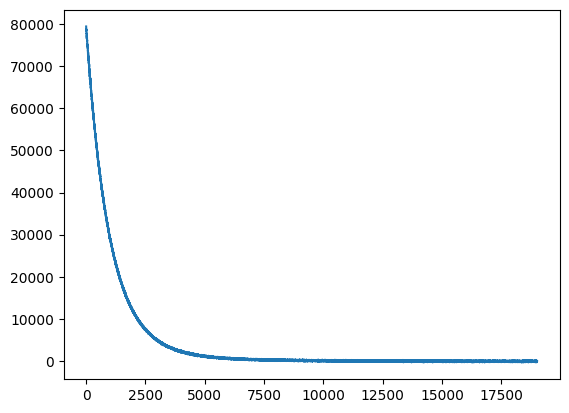

In [50]:
params_aux = None
losses_aux = []
for adam in adam_seq:
    svi = pyro.infer.SVI(model_aux, guide_aux, adam, elbo)
    params_aux, new_losses = do_svi(svi, params = params_aux)
    losses_aux += new_losses
plt.plot(losses_aux)
guide_aux.eval()
with param_store.scope(params_aux):
    pred_aux = Predictive(model_aux, guide = guide_aux, num_samples = 100)
    Y_pred_aux = pred_aux.get_samples(X_pred = X_test)['mu_pred']

In [51]:
mse_aux_mm = (Y_pred_aux_mm - Y_train_full_sc).pow(2).mean(dim=0)
mse_aux = (Y_pred_aux - Y_train_full_sc).pow(2).mean(dim=0)
rmse_aux_mm = mse_aux_mm.sqrt()
rmse_aux = mse_aux.sqrt()

data_std = Y_train_full_sc.std(dim=0)

rmse_aux_mm_normed = rmse_aux_mm / data_std
rmse_aux_normed = rmse_aux / data_std

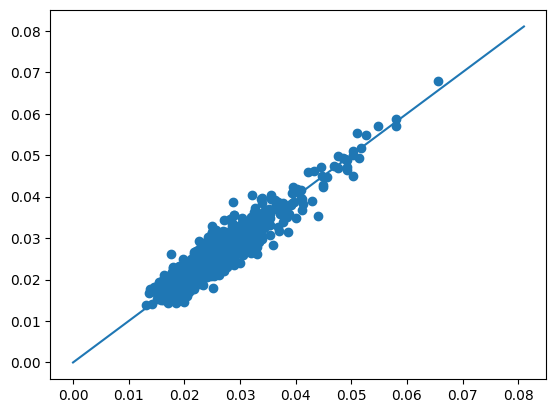

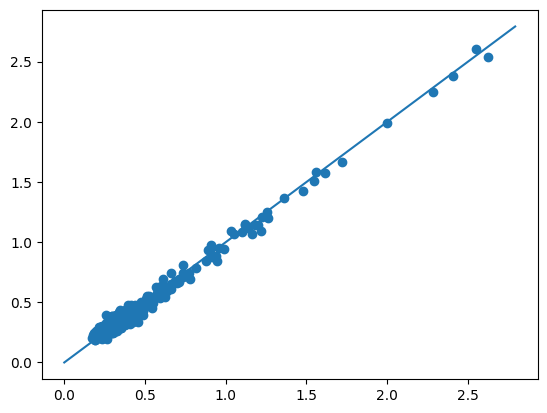

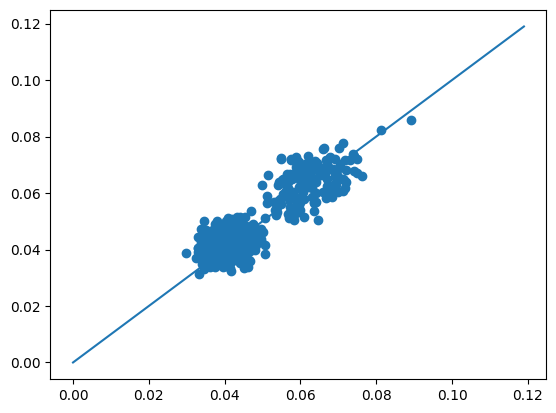

In [52]:
# Points below the line indicate that the multimodal model predicted aux values better than the unimodal model
# Points above the line indicate that the unimodal model predicted aux values better than the multimodal model

for idx in range(rmse_aux.shape[-1]):
    linemax = max(rmse_aux_normed[:,idx].max(), rmse_aux_mm_normed[:,idx].max()) + min(rmse_aux_normed[:,idx].min(), rmse_aux_mm_normed[:,idx].min())
    plt.scatter(rmse_aux_normed[:,idx], rmse_aux_mm_normed[:,idx])
    plt.plot([0,linemax],[0,linemax])
    plt.show()

## Joint multimodal model

In [53]:
# Joint x = X_train_full
# first combine them all then replace the missing values in the main modality with nan
n_comp = Y_train_ts_pca.shape[-1]

Y_train_joint = torch.cat([Y_train_full_ts_pca, Y_train_full_sc], dim = -1)

for i in range(Y_train_joint.shape[0]):
    # If X_train_full[i] is not in X_train, then replance Y_train_joint[i,0] with torch.nan
    if not (X_train_full[i] == X_train).all(dim = -1).any():
        Y_train_joint[i,0:n_comp] = torch.nan

In [54]:
model_joint = RegBNN.from_data(X_train_full, Y_train_joint, hidden_widths = hidden_widths)
guide_joint = RegBNNGuide(model_joint)

hmc_joint = pyro.infer.NUTS(model_joint.no_missing())

Step 1000, Elbo loss: 52555.2 +/- 28358.4 (slope = -48553.471 +/- 459.791 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 27187.9 +/- 4718.6 (slope = -7851.856 +/- 142.658 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 23129.0 +/- 1305.1 (slope = -2158.862 +/- 42.186 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 21522.4 +/- 756.3 (slope = -1156.438 +/- 38.873 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 20847.8 +/- 405.0 (slope = -312.799 +/- 39.720 loss/k-iter, p-value = 0.000) + 
Step 6000, Elbo loss: 20577.5 +/- 383.4 (slope = -251.829 +/- 38.874 loss/k-iter, p-value = 0.000) + 
Step 7000, Elbo loss: 20406.1 +/- 383.9 (slope = -176.123 +/- 40.575 loss/k-iter, p-value = 0.000) + 
Step 8000, Elbo loss: 20253.3 +/- 360.4 (slope = -89.645 +/- 39.089 loss/k-iter, p-value = 0.000) + 
Step 9000, Elbo loss: 20179.8 +/- 354.4 (slope = -82.451 +/- 38.492 loss/k-iter, p-value = 0.000) + 
Step 10000, Elbo loss: 20097.7 +/- 370.7 (slope = -120.515 +/- 39.907 los

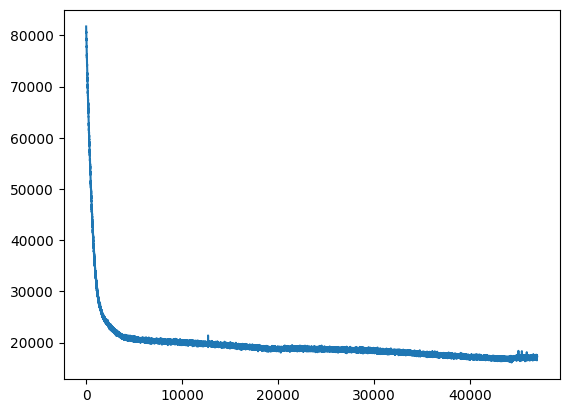

In [55]:
if method == "mcmc":
    mcmc_joint = pyro.infer.MCMC(hmc_joint, num_samples = 100, warmup_steps = 100)
    mcmc_joint.run(X_pred = X_test)
    pred_joint = Predictive(model_joint, mcmc_joint.get_samples())
    Y_pred_joint = pred.get_samples(X_pred = X_test)['mu_pred']
elif method == "svi":
    params_joint = None
    losses_joint = []
    for adam in adam_seq:
        svi_joint = pyro.infer.SVI(model_joint, guide_joint, adam, elbo)
        params_joint, new_losses = do_svi(svi_joint, params = params_joint)
        losses_joint += new_losses
    plt.plot(losses_joint)
    guide_joint.eval()
    with param_store.scope(params_joint):
        pred_joint = Predictive(model_joint, guide = guide_joint, num_samples = 100)
        Y_pred_joint = pred_joint.get_samples(X_pred = X_test)['mu_pred']

In [56]:
Y_pred_joint_mainonly = Y_pred_joint[...,0:n_comp]
Y_pred_joint_mainonly

tensor([[[ 4.3118e+00,  2.6383e+00, -9.6037e-01,  ...,  9.7959e-03,
          -1.2208e+00,  3.8214e+00],
         [ 4.7753e+00,  2.3643e+00, -5.5030e-01,  ...,  5.0386e-01,
          -1.3019e+00,  4.0666e+00],
         [ 4.1513e+00,  1.3885e+00, -3.5392e-01,  ...,  1.1359e+00,
          -7.5801e-01,  3.7990e+00],
         ...,
         [-8.3089e+00,  2.9389e+00, -1.1185e+00,  ..., -5.7258e-01,
           3.3717e-02,  5.2075e-01],
         [-8.1100e+00,  2.4423e+00, -1.4315e+00,  ..., -2.6932e-01,
          -1.4909e-01,  4.4807e-01],
         [-6.7282e+00,  1.8642e+00, -1.7089e+00,  ..., -1.1522e-01,
          -5.1330e-02,  6.0760e-01]],

        [[ 2.4234e+00,  2.5928e+00, -4.6330e-01,  ...,  1.8110e+00,
          -1.3339e+00,  9.8011e-01],
         [ 4.0924e+00,  2.1087e+00, -4.7250e-01,  ...,  1.4839e+00,
          -9.3040e-01,  8.2042e-01],
         [ 5.4540e+00,  1.8849e+00, -6.6974e-01,  ...,  1.2459e+00,
          -6.6746e-01,  1.6623e+00],
         ...,
         [-7.9914e+00,  2

In [58]:
Y_bias_joint = (Y_pred_joint_mainonly.mean(dim=0) - Y_test_ts_pca).pow(2).sum(dim = -1).sqrt()
Y_var_fakemm_pca = Y_pred_joint_mainonly.var(dim=0).sum(dim=-1)

Y_mean_joint = Y_pred_joint_mainonly.mean(dim=0)
Y_cov_joint = batch_cov(Y_pred_joint_mainonly.permute(1,2,0))
Y_zscore_joint = mv_zscore(Y_test_ts_pca, Y_mean_joint, Y_cov_joint)

Text(0, 0.5, 'Joint Multimodal')

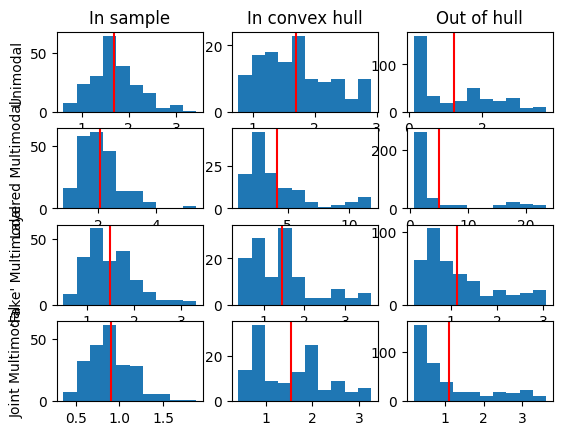

In [60]:
fig, axs = plt.subplots(4,3)
# Unimodal, in sample
axs[0,0].hist(Y_zscore_pca[in_sample])
axs[0,0].axvline(Y_zscore_pca[in_sample].mean(), color="red")
# Unimodal, in hull
axs[0,1].hist(Y_zscore_pca[in_hull])
axs[0,1].axvline(Y_zscore_pca[in_hull].mean(), color="red")
# Unimodal, out hull
axs[0,2].hist(Y_zscore_pca[out_hull])
axs[0,2].axvline(Y_zscore_pca[out_hull].mean(), color="red")
# Multimodal, in sample
axs[1,0].hist(Y_zscore_mm_pca[in_sample])
axs[1,0].axvline(Y_zscore_mm_pca[in_sample].mean(), color="red")
# Multimodal, in hull
axs[1,1].hist(Y_zscore_mm_pca[in_hull])
axs[1,1].axvline(Y_zscore_mm_pca[in_hull].mean(), color="red")
# Multimodal, out hull
axs[1,2].hist(Y_zscore_mm_pca[out_hull])
axs[1,2].axvline(Y_zscore_mm_pca[out_hull].mean(), color="red")
# 'Fake' Multimodal, in sample
axs[2,0].hist(Y_zscore_fakemm_pca[in_sample])
axs[2,0].axvline(Y_zscore_fakemm_pca[in_sample].mean(), color="red")
# 'Fake' Multimodal, in hull
axs[2,1].hist(Y_zscore_fakemm_pca[in_hull])
axs[2,1].axvline(Y_zscore_fakemm_pca[in_hull].mean(), color="red")
# 'Fake' Multimodal, out hull
axs[2,2].hist(Y_zscore_fakemm_pca[out_hull])
axs[2,2].axvline(Y_zscore_fakemm_pca[out_hull].mean(), color="red")
# Joint Multimodal, in sample
axs[3,0].hist(Y_zscore_joint[in_sample])
axs[3,0].axvline(Y_zscore_joint[in_sample].mean(), color="red")
# Joint Multimodal, in hull
axs[3,1].hist(Y_zscore_joint[in_hull])
axs[3,1].axvline(Y_zscore_joint[in_hull].mean(), color="red")
# Joint Multimodal, out hull
axs[3,2].hist(Y_zscore_joint[out_hull])
axs[3,2].axvline(Y_zscore_joint[out_hull].mean(), color="red")

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("Layered Multimodal")
axs[2,0].set_ylabel("'Fake' Multimodal")
axs[3,0].set_ylabel("Joint Multimodal")